<a href="https://colab.research.google.com/github/swasfish-code/python/blob/main/IIT_H_Data_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

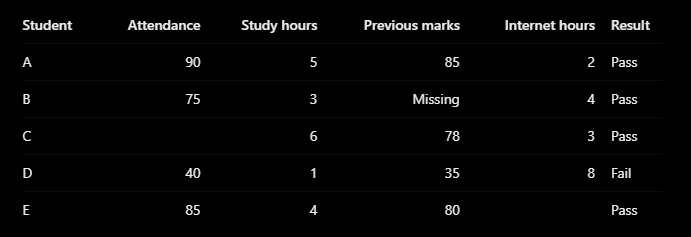

In [ ]:
# Data pre-processing is the format of converting the raw data into suitable and consistent format for giving it as input to the ML model.

In [ ]:
import pandas as pd
import numpy as np

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    MinMaxScaler,
    LabelEncoder
)
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
data = {
    "Student": ["A", "B", "C", "D", "E", "F"],
    "Attendance": [90, 75, np.nan, 40, 85, 70],
    "Study_Hours": [5, 3, 6, 1, 4, np.nan],
    "Previous_Marks": [85, np.nan, 78, 35, 80, 65],
    "Internet_Hours": [2, 4, 3, 8, np.nan, 5],
    "Branch": ["CSE", "ECE", "CSE", "MECH", "ECE", "CSE"],
    "Result": ["Pass", "Pass", "Pass", "Fail", "Pass", "Fail"]
}

df = pd.DataFrame(data)

df

,Student,Attendance,Study_Hours,Previous_Marks,Internet_Hours,Branch,Result
0,A,90.0,5.0,85.0,2.0,CSE,Pass
1,B,75.0,3.0,NaN,4.0,ECE,Pass
2,C,NaN,6.0,78.0,3.0,CSE,Pass
3,D,40.0,1.0,35.0,8.0,MECH,Fail
4,E,85.0,4.0,80.0,NaN,ECE,Pass
5,F,70.0,NaN,65.0,5.0,CSE,Fail


In [ ]:
df.head(1)

,Student,Attendance,Study_Hours,Previous_Marks,Internet_Hours,Branch,Result
0,A,90.0,5.0,85.0,2.0,CSE,Pass


In [ ]:
df.shape

(6, 7)

In [ ]:
row, col = df.shape

In [ ]:
row

6

In [ ]:
col

7

In [ ]:
df.dtypes

,0
Student,object
Attendance,float64
Study_Hours,float64
Previous_Marks,float64
Internet_Hours,float64
Branch,object
Result,object


In [ ]:
df.isnull().sum()

,0
Student,0
Attendance,1
Study_Hours,1
Previous_Marks,1
Internet_Hours,1
Branch,0
Result,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6 entries, 0 to 5
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Student         6 non-null      object 
 1   Attendance      5 non-null      float64
 2   Study_Hours     5 non-null      float64
 3   Previous_Marks  5 non-null      float64
 4   Internet_Hours  5 non-null      float64
 5   Branch          6 non-null      object 
 6   Result          6 non-null      object 
dtypes: float64(4), object(3)
memory usage: 468.0+ bytes


In [ ]:
#percentage of the missing values in each column
(df.isnull().sum()*100/len(df)).round(2)

,0
Student,0.00
Attendance,16.67
Study_Hours,16.67
Previous_Marks,16.67
Internet_Hours,16.67
Branch,0.00
Result,0.00


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.drop_duplicates()

,Student,Attendance,Study_Hours,Previous_Marks,Internet_Hours,Branch,Result
0,A,90.0,5.0,85.0,2.0,CSE,Pass
1,B,75.0,3.0,NaN,4.0,ECE,Pass
2,C,NaN,6.0,78.0,3.0,CSE,Pass
3,D,40.0,1.0,35.0,8.0,MECH,Fail
4,E,85.0,4.0,80.0,NaN,ECE,Pass
5,F,70.0,NaN,65.0,5.0,CSE,Fail


In [ ]:
#for each branch, how many students i have?
(df["Branch"] == "CSE").sum()

np.int64(3)

In [ ]:
df["Branch"].value_counts()

,count
Branch,
CSE,3
ECE,2
MECH,1


In [ ]:
df["Result"].value_counts()

,count
Result,
Pass,4
Fail,2


In [ ]:
marks = pd.DataFrame({
    "Name": ["Amit", "Neha", "Rahul", "Priya"],
    "Marks": [80, np.nan, 65, 90]
})

print(marks)

    Name  Marks
0   Amit   80.0
1   Neha    NaN
2  Rahul   65.0
3  Priya   90.0


In [ ]:
marks.dropna()

,Name,Marks
0,Amit,80.0
2,Rahul,65.0
3,Priya,90.0


In [ ]:
marks

,Name,Marks
0,Amit,80.0
1,Neha,NaN
2,Rahul,65.0
3,Priya,90.0


In [ ]:
marks2 = marks


In [ ]:
marks2

,Name,Marks
0,Amit,80.0
1,Neha,NaN
2,Rahul,65.0
3,Priya,90.0


In [ ]:
marks2.dropna(inplace = True)

In [ ]:
marks2

,Name,Marks
0,Amit,80.0
2,Rahul,65.0
3,Priya,90.0


In [ ]:
marks

,Name,Marks
0,Amit,80.0
2,Rahul,65.0
3,Priya,90.0


In [ ]:
marks3 = marks.copy()
marks3.dropna(inplace= True)

In [ ]:
marks3

,Name,Marks
0,Amit,80.0
2,Rahul,65.0
3,Priya,90.0


In [ ]:
marks

,Name,Marks
0,Amit,80.0
1,Neha,NaN
2,Rahul,65.0
3,Priya,90.0


In [ ]:
df["Result"].value_counts()

,count
Result,
Pass,4
Fail,2


In [ ]:
#what % of students passed and failed?

In [ ]:
df["Result"].value_counts(normalize= True)

,proportion
Result,
Pass,0.666667
Fail,0.333333


In [ ]:
(df["Result"].value_counts(normalize= True)*100).round(2)

,proportion
Result,
Pass,66.67
Fail,33.33


In [ ]:
marks

,Name,Marks
0,Amit,80.0
1,Neha,NaN
2,Rahul,65.0
3,Priya,90.0


In [ ]:
(80+65+90)/3

78.33333333333333

In [ ]:
marks.fillna(marks["Marks"].mean())

,Name,Marks
0,Amit,80.000000
1,Neha,78.333333
2,Rahul,65.000000
3,Priya,90.000000


In [ ]:
marks

,Name,Marks
0,Amit,80.0
1,Neha,NaN
2,Rahul,65.0
3,Priya,90.0


In [ ]:
marks.fillna(marks["Marks"].mean(), inplace = True)

In [ ]:
marks

,Name,Marks
0,Amit,80.000000
1,Neha,78.333333
2,Rahul,65.000000
3,Priya,90.000000


In [ ]:
salary = pd.DataFrame({
    "Salary": [20000, 22000, 25000, 28000, 500000, np.nan]
})

In [ ]:
salary["Salary"] = salary["Salary"].fillna(
    salary["Salary"].median()
)

In [ ]:
salary

,Salary
0,20000.0
1,22000.0
2,25000.0
3,28000.0
4,500000.0
5,25000.0


In [ ]:
marks = pd.DataFrame({
    "Maths": [80, 70, np.nan, 90],
    "Science": [75, np.nan, 85, 95]
})

imputer = SimpleImputer(strategy="mean")


filled_array = imputer.fit_transform(marks)

filled_marks = pd.DataFrame(
    filled_array,
    columns=marks.columns
)

print(filled_marks)


   Maths  Science
0   80.0     75.0
1   70.0     85.0
2   80.0     85.0
3   90.0     95.0
